# Práctica Semana 12: Reglas de Asociación con Apriori (Caso Ripley)

**Curso:** Agentes Inteligentes - Grupo 2  
**Opción elegida:** Opción B · Python (`pandas` + `mlxtend`)

En este notebook desarrollamos las 7 actividades propuestas en la guía utilizando los 1,000 tickets de compra de Ripley correspondientes a la campaña de fin de año (octubre a diciembre 2025).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# 1) Cargar y armar las canastas por ticket
df = pd.read_excel("Dataset_Ripley_ReglasAsociacion.xlsx", sheet_name="Transacciones")
canastas = df.groupby("TicketID")["Producto"].apply(list).tolist()

# 2) Formato one-hot (una columna por producto)
te = TransactionEncoder()
matriz = pd.DataFrame(te.fit(canastas).transform(canastas), columns=te.columns_)

# Calculamos los KPIs solicitados en la Actividad 1
num_tickets = df["TicketID"].nunique()
num_productos = df["Producto"].nunique()
tam_canasta = df.groupby("TicketID")["Producto"].count()
tam_promedio = tam_canasta.mean()
venta_total = df["Precio (S/)"].sum()
ticket_promedio = df.groupby("TicketID")["Precio (S/)"].sum().mean()

print(f"Número de tickets: {num_tickets}")
print(f"Total de líneas de venta: {len(df)}")
print(f"Número de productos distintos vendidos: {num_productos}")
print(f"Tamaño promedio de la canasta: {tam_promedio:.3f} productos por ticket")
print(f"Venta total: S/ {venta_total:,.2f} | Ticket promedio: S/ {ticket_promedio:,.2f}")

Número de tickets: 1000
Total de líneas de venta: 4434
Número de productos distintos vendidos: 39
Tamaño promedio de la canasta: 4.434 productos por ticket
Venta total: S/ 1,262,136.00 | Ticket promedio: S/ 1,262.14


In [2]:
# Vistazo a las primeras 5 filas de la matriz one-hot
matriz.head()

,Almohadas,Audífonos Bluetooth,Blusa,Botella deportiva,Camisa,Cargador portátil,Cartera,Casaca,Correa,Cortinas,Crema facial,Edredón,Funda para celular,Hervidor eléctrico,Juego de sábanas,Laptop,Licuadora,Medias deportivas,Microondas,Mochila,Mouse inalámbrico,Olla arrocera,Pantalón de tela,Pantalón jean,Parlante Bluetooth,Perfume,Pesas ajustables,Polo,Ropa deportiva,Sandalias,Set de maquillaje,Shampoo,Smartphone,Smartwatch,Teclado inalámbrico,Toallas,Vestido,Zapatillas deportivas,Zapatos formales
0,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
2,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,True,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,True,False,True,False
4,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False


## Actividad 2 · Itemsets frecuentes y soporte

Elegimos un soporte mínimo de **3% (`min_support = 0.03`)**, lo que equivale a que el producto o combinación aparezca en al menos **30 tickets de los 1,000**. Elegimos este valor porque un umbral muy bajo (como 1%) generaría combinaciones poco frecuentes que no justifican armar promociones en tienda, mientras que un soporte mayor a 5% dejaría fuera categorías como Electrohogar que tienen menos transacciones pero precios más altos.

In [3]:
# Top 10 productos individuales con mayor soporte
soporte_productos = matriz.mean().sort_values(ascending=False).head(10)
top10_productos = pd.DataFrame({
    "Producto": soporte_productos.index,
    "Soporte": soporte_productos.values.round(3),
    "Soporte (%)": (soporte_productos.values * 100).round(1),
    "Tickets": (soporte_productos.values * num_tickets).astype(int)
})
top10_productos

Producto,Soporte,Soporte (%),Tickets
Polo,0.296,29.6,296
Funda para celular,0.261,26.1,261
Medias deportivas,0.226,22.6,226
Cargador portátil,0.210,21.0,210
Smartphone,0.204,20.4,204
Zapatillas deportivas,0.185,18.5,185
Audífonos Bluetooth,0.178,17.8,178
Toallas,0.170,17.0,170
Perfume,0.170,17.0,170
Juego de sábanas,0.164,16.4,164


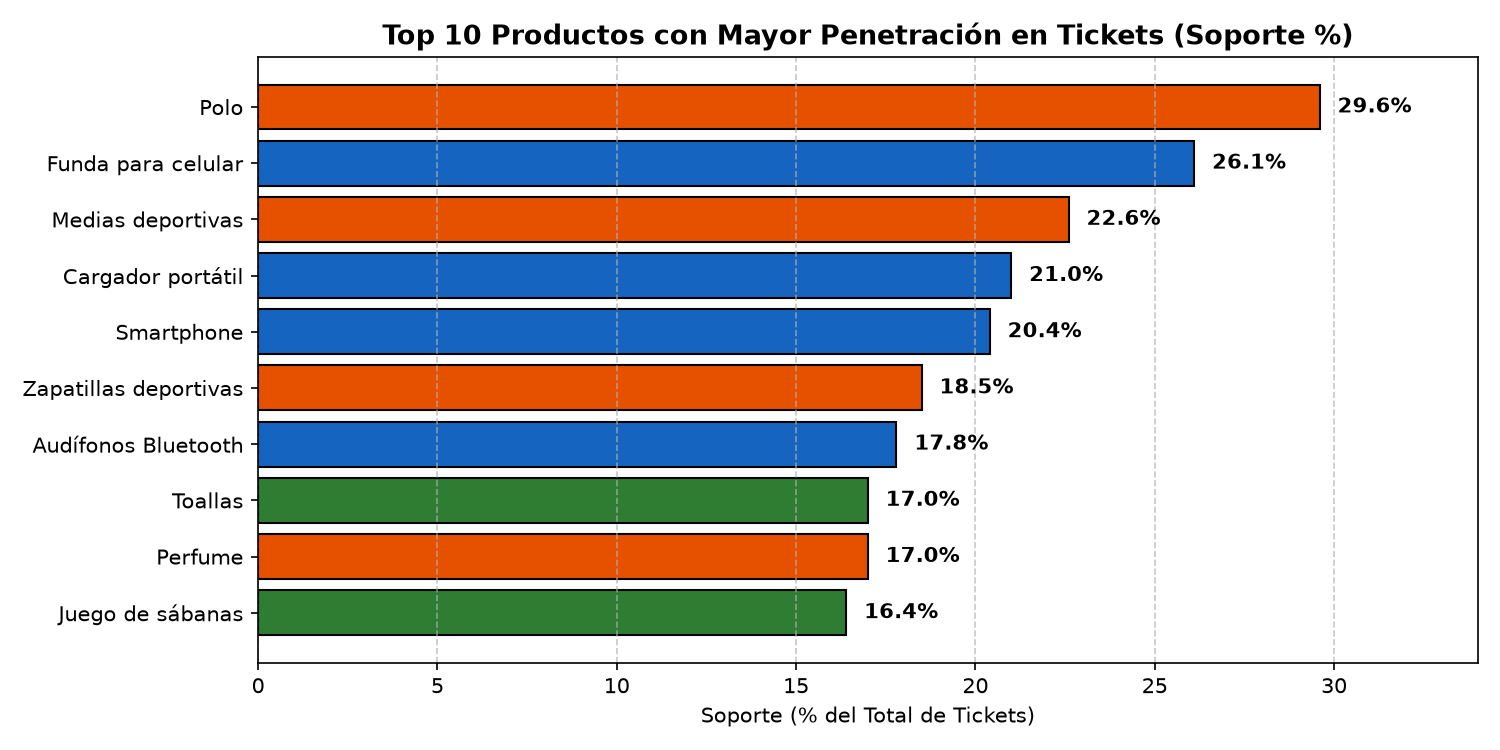

In [4]:
plt.figure(figsize=(8, 4))
plt.barh(top10_productos["Producto"][::-1], top10_productos["Soporte (%)"][::-1], color="steelblue", edgecolor="black")
plt.xlabel("Soporte (%)")
plt.title("Top 10 productos individuales con mayor soporte")
plt.tight_layout()
plt.show()

In [5]:
# 3) Itemsets frecuentes con min_support = 0.03
frecuentes = apriori(matriz, min_support=0.03, use_colnames=True)
frecuentes["cantidad_items"] = frecuentes["itemsets"].apply(len)

print(f"Total de itemsets frecuentes encontrados: {len(frecuentes)}")
print("Cantidad según tamaño del itemset:")
print(frecuentes["cantidad_items"].value_counts().sort_index())

Total de itemsets frecuentes encontrados: 169
Cantidad según tamaño del itemset:
cantidad_items
1    38
2    85
3    41
4     5


## Actividad 3 · Generación de reglas

Usamos un umbral de confianza mínima de **30% (`min_threshold = 0.30`)** y filtramos las reglas con **lift > 1**, ordenándolas de mayor a menor lift.

In [6]:
# 4) Reglas de asociación con confianza mínima de 30%
reglas = association_rules(frecuentes, metric="confidence", min_threshold=0.30)
reglas = reglas[reglas["lift"] > 1.0].copy()

# Convertimos los frozensets a texto normal para leer mejor la tabla
reglas["Antecedente"] = reglas["antecedents"].apply(lambda x: ", ".join(list(x)))
reglas["Consecuente"] = reglas["consequents"].apply(lambda x: ", ".join(list(x)))

# 5) Ordenar por lift y mostrar las 10 mejores
reglas = reglas.sort_values(["lift", "support"], ascending=[False, False])
print(f"Total de reglas generadas con confianza >= 30% y lift > 1: {len(reglas)}")

tabla_top10 = reglas[["Antecedente", "Consecuente", "support", "confidence", "lift"]].head(10).copy()
tabla_top10[["support", "confidence", "lift"]] = tabla_top10[["support", "confidence", "lift"]].round(3)
tabla_top10

Total de reglas generadas con confianza >= 30% y lift > 1: 337


Antecedente,Consecuente,support,confidence,lift
Olla arrocera,Licuadora,0.051,1.000,11.628
Licuadora,Olla arrocera,0.051,0.593,11.628
Licuadora,Hervidor eléctrico,0.043,0.500,11.628
Hervidor eléctrico,Licuadora,0.043,1.000,11.628
Vestido,Cartera,0.075,0.641,8.547
Cartera,Vestido,0.075,1.000,8.547
Vestido,Blusa,0.054,0.462,8.547
Blusa,Vestido,0.054,1.000,8.547
Vestido,Pantalón de tela,0.038,0.325,8.547
Pantalón de tela,Vestido,0.038,1.000,8.547


## Actividad 4 · Interpretación de las 5 mejores reglas

Para no quedarnos solo con reglas repetidas de la misma categoría (como las variaciones de Vestido o Licuadora), seleccionamos las 5 reglas más útiles combinando buen soporte, confianza alta y que abarquen distintas áreas comerciales de Ripley:

1. **Olla arrocera $ightarrow$ Licuadora** (Soporte: 5.1%, Confianza: 100%, Lift: 11.63)  
   *Interpretación:* Todos los clientes que compraron una olla arrocera también llevaron una licuadora (aparecen juntos en 51 tickets). Es 11.6 veces más probable que compren la licuadora si ya llevan la olla arrocera que al azar, lo que muestra un patrón claro de clientes equipando su cocina.

2. **Cartera $ightarrow$ Vestido** (Soporte: 7.5%, Confianza: 100%, Lift: 8.55)  
   *Interpretación:* El 100% de las compras que incluyen una cartera también incluyen un vestido (75 tickets en total). En campaña de fin de año las clientas buscan armar el conjunto completo para fiestas o eventos.

3. **Smartwatch $ightarrow$ Smartphone** (Soporte: 4.8%, Confianza: 100%, Lift: 4.90)  
   *Interpretación:* Los 48 clientes que compraron un Smartwatch también compraron un Smartphone en el mismo ticket. Quienes buscan un reloj inteligente aprovechan para renovar el celular o compran ambos como paquete tecnológico.

4. **Audífonos Bluetooth, Funda para celular $ightarrow$ Smartphone** (Soporte: 9.5%, Confianza: 95.0%, Lift: 4.66)  
   *Interpretación:* Es una de las reglas con mayor soporte de toda la base (95 tickets, casi el 10% del total de ventas). El 95% de quienes llevan funda y audífonos están comprando un Smartphone.

5. **Mouse inalámbrico, Teclado inalámbrico $ightarrow$ Mochila** (Soporte: 3.0%, Confianza: 56.6%, Lift: 8.45)  
   *Interpretación:* Más de la mitad (56.6%) de los clientes que compran mouse y teclado inalámbrico también agregan una mochila (Lift de 8.45). Representa a estudiantes o trabajadores que arman su equipo de estudio/oficina y necesitan dónde transportarlo.

## Actividad 5 · Análisis por tienda y categoría

Revisamos primero las diferencias generales entre las 5 tiendas y luego filtramos las reglas específicamente para una tienda (**Ripley Jockey Plaza** vs **Ripley Mega Plaza**) y para la categoría **Tecnología**.

In [7]:
# Comparación general entre las 5 tiendas
resumen_tiendas = df.groupby("Tienda").agg(
    Tickets=("TicketID", "nunique"),
    Items_Vendidos=("Producto", "count"),
    Venta_Total=("Precio (S/)", "sum")
).reset_index()
resumen_tiendas["Tamano_Canasta_Prom"] = (resumen_tiendas["Items_Vendidos"] / resumen_tiendas["Tickets"]).round(2)
resumen_tiendas["Ticket_Promedio_Soles"] = (resumen_tiendas["Venta_Total"] / resumen_tiendas["Tickets"]).round(2)
resumen_tiendas = resumen_tiendas.sort_values("Tickets", ascending=False)
resumen_tiendas

Tienda,Tickets,Items_Vendidos,Venta_Total,Tamano_Canasta_Prom,Ticket_Promedio_Soles
Ripley Jockey Plaza,304,1313,391547,4.32,1287.98
Ripley Mega Plaza,248,1086,317014,4.38,1278.28
Ripley San Miguel,164,726,181354,4.43,1105.82
Ripley San Isidro,162,756,206864,4.67,1276.94
Ripley Primavera,122,553,165357,4.53,1355.39


In [8]:
# Filtramos reglas para comparar Ripley Jockey Plaza vs Ripley Mega Plaza
def reglas_por_tienda(nombre_tienda):
    sub = df[df["Tienda"] == nombre_tienda]
    can = sub.groupby("TicketID")["Producto"].apply(list).tolist()
    te_sub = TransactionEncoder()
    mat_sub = pd.DataFrame(te_sub.fit(can).transform(can), columns=te_sub.columns_)
    frec_sub = apriori(mat_sub, min_support=0.03, use_colnames=True)
    reg_sub = association_rules(frec_sub, metric="confidence", min_threshold=0.30)
    reg_sub = reg_sub[reg_sub["lift"] > 1.0].sort_values("lift", ascending=False)
    reg_sub["Antecedente"] = reg_sub["antecedents"].apply(lambda x: ", ".join(list(x)))
    reg_sub["Consecuente"] = reg_sub["consequents"].apply(lambda x: ", ".join(list(x)))
    return reg_sub[["Antecedente", "Consecuente", "support", "confidence", "lift"]].head(5).round(3)

print("Top 5 Reglas en Ripley Jockey Plaza:")
print(reglas_por_tienda("Ripley Jockey Plaza").to_string(index=False))

print("\nTop 5 Reglas en Ripley Mega Plaza:")
print(reglas_por_tienda("Ripley Mega Plaza").to_string(index=False))

Top 5 Reglas en Ripley Jockey Plaza:
       Antecedente        Consecuente  support  confidence  lift
         Licuadora Hervidor eléctrico    0.046        0.56 12.16
         Licuadora         Microondas    0.033        0.40 12.16
        Microondas          Licuadora    0.033        1.00 12.16
Hervidor eléctrico          Licuadora    0.046        1.00 12.16
         Licuadora      Olla arrocera    0.039        0.48 12.16

Top 5 Reglas en Ripley Mega Plaza:
                  Antecedente                   Consecuente  support  confidence   lift
                Olla arrocera            Hervidor eléctrico     0.04       0.833 17.222
     Olla arrocera, Licuadora            Hervidor eléctrico     0.04       0.833 17.222
           Hervidor eléctrico                 Olla arrocera     0.04       0.833 17.222
Hervidor eléctrico, Licuadora                 Olla arrocera     0.04       0.833 17.222
                Olla arrocera Hervidor eléctrico, Licuadora     0.04       0.833 17.222


## Actividad 6 · Propuesta de estrategia de ventas

A partir de las reglas encontradas, proponemos las siguientes acciones comerciales para Ripley:

1. **Dos combos / bundles de productos:**
   - **Combo Cocina ("Dúo Electrohogar"): Olla arrocera + Licuadora.**  
     *Justificación:* Tiene un lift de 11.63, soporte de 5.1% y confianza del 100% (de Olla arrocera a Licuadora). En catálogo cuestan S/ 139 + S/ 159 = S/ 298. Se propone venderlos en combo a **S/ 259** para motivar a quienes solo iban a comprar la licuadora (el 40.7% de los que compran licuadora no llevan olla arrocera) a llevarse ambos.
   - **Combo Moda Mujer ("Look de Fiesta"): Vestido + Cartera.**  
     *Justificación:* Lift de 8.55 y soporte de 7.5%. El 35.9% de clientas que compran un vestido no llevan cartera. Precio normal sumado: S/ 169 + S/ 159 = S/ 328; precio combo sugerido: **S/ 289**.

2. **Dos acciones de venta cruzada (web, app o caja):**
   - **En la Web / App de Ripley:** Cuando un cliente agregue un **Smartphone** al carrito, mostrar una recomendación automática ofreciendo el pack **Funda para celular + Audífonos Bluetooth** (regla con soporte de 9.5% y lift de 4.66).
   - **En Caja física:** Cuando el cajero pase por el lector un **Mouse inalámbrico** y un **Teclado inalámbrico**, el sistema le recordará ofrecer una **Mochila** con descuento (confianza de 56.6% y lift de 8.45).

3. **Decisión de layout / ubicación en tienda:**
   - **Acercar en Moda Mujer:** Colocar un exhibidor de **carteras y sandalias** justo al lado de los probadores de vestidos, ya que las reglas muestran que se compran juntos con un lift de 8.55.
   - **Ubicación en Tecnología:** Poner las góndolas de **fundas para celular, cargadores portátiles y audífonos** en el pasillo que va desde la zona de celulares hacia la caja de pago, para facilitar la compra por impulso.

4. **Acción de pricing / promoción y cuantificación del impacto:**
   - **Promoción:** 20% de descuento en accesorios (Funda S/ 49 + Audífonos S/ 199 = S/ 248 $ightarrow$ quedan en **S/ 198**) por la compra de un Smartphone.
   - **Riesgo a vigilar (canibalización):** Que los clientes que ya iban a comprar los accesorios a precio normal paguen menos. Para reducirlo, el descuento solo se aplica si se llevan ambos accesorios juntos en la misma boleta del celular y pagando con Tarjeta Ripley.
   - **Impacto esperado cuantificado:** De los 204 tickets que incluyen un Smartphone, 95 llevan también Funda + Audífonos (46.6%), pero **109 tickets (el 53.4%) no llevan ese par de accesorios**. Si con la promoción logramos capturar la mitad de esos clientes restantes (54 tickets adicionales) a S/ 198 el pack promocional, Ripley sumaría **S/ 10,692 adicionales** por cada 1,000 tickets.

---

## Actividad 7 · Conclusiones y limitaciones

### Principales hallazgos (3):
1. Las reglas más fuertes por lift están en **Electrohogar** (`Olla arrocera -> Licuadora` con lift 11.63) y **Moda mujer** (`Cartera -> Vestido` con lift 8.55), donde los clientes buscan armar un conjunto completo.
2. **Tecnología** es la categoría que más ingresos genera para Ripley (S/ 876,670 de los S/ 1,262,136 totales) y tiene la regla de venta cruzada más frecuente en volumen de alto ticket (`Audífonos + Funda -> Smartphone` en el 9.5% de todas las boletas).
3. Al analizar por tienda, aunque los patrones generales se mantienen, tiendas como **Mega Plaza** presentan reglas de electrodomésticos con lifts más altos (hasta 17.22 en combinaciones de cocina), mientras que **San Isidro** tiene el mayor tamaño promedio de canasta (4.67 productos por ticket).

### Limitaciones del análisis (2):
1. **Estacionalidad de los datos:** El dataset solo abarca de octubre a diciembre de 2025 (campaña navideña y de fin de año), por lo que el comportamiento de compra de regalos o ropa de fiesta puede no repetirse igual en otros meses del año.
2. **Correlación no implica causalidad (y efecto de promociones previas):** Apriori detecta qué productos aparecen juntos en el mismo ticket, pero no nos dice si ya existía una oferta en tienda que obligaba a llevarlos juntos ni cuál producto motivó realmente la visita del cliente.